# Extended Data: single-cell ATAC panels

Makes two Extended Data panels from the multiome ATAC data.

Cheng, Stok Ranen et al., bioRxiv, doi:10.64898/2026.05.14.725081.

- **ED 4a**: ATAC coverage ratio along the genome, trisomies in red; TKO only (section: Trisomy detection)
- **ED 6b**: accessibility of WT state-specific CREs across states and genotypes (section: State-specific CRE clusters)

Figures go through `out_path()` (`paths.R`), which maps `figs/...` to `git_test/figs/...`.

## Initialization

In [1]:
source("paths.R")
save_figure = F  # TRUE also writes every figure to git_test/ (see show_fig() in paths.R)

In [2]:
library(misha)
library(misha.ext)
library(ggplot2)
library(dplyr)
library(tibble)
library(zoo)

source(file.path(repo_dir, "scripts/ATAC_preprocessing.r"))

In [3]:
gset_genome("mm10")

## ED 4a: trisomy detection

- Sums the marginal ATAC tracks of Dnmt-TKO KO cells and WT atlas (`WT_lg` + `WT_sm`) in 100 kb windows.
- Normalizes each window by its track's genome-wide mean; plots log2(TKO / WT). chrX, chrY, chrM dropped.
- chr6 is coloured red (trisomic in Dnmt-TKO).

Notes:
- Windows are 100 kb, not 500 bp.
- Reference is the WT atlas, not host cells.
- Plots Dnmt-TKO; change the track names to plot Dnmt-DKO or Tet-TKO.
- The 500-window rolling mean is not plotted; `ylim(-1, 1)` drops windows outside that range.

In [4]:
mut_track = "mut_multi2.DNMT_TKO_KO.marginal"
nm = "DNMT TKO KO"

wt_track = "mut_multi2.WT_lg.marginal+mut_multi2.WT_sm.marginal"

In [5]:
ge =  gextract.left_join(c(mut_track, wt_track), iterator = 1e+5, intervals = gintervals.all())

In [6]:
plot_df = data.frame("chrom" = ge$chrom, "start" = ge$start, 
                     "trend_diff" = log2((ge[,4]/mean(ge[,4], na.rm=T))/(ge[,5]/mean(ge[,5], na.rm=T)))) %>%
    filter(!chrom %in% c("chrX", "chrY", "chrM"))
plot_df$chrom = factor(plot_df$chrom, levels = paste0("chr", 1:19))
plot_df = plot_df %>% arrange(chrom, start) %>% mutate(window = row_number())
chrom_lims = cumsum(plot_df %>% group_by(chrom) %>% summarise(nrow = n()) %>% pull(nrow)) 

plot_df$rollmean <- rollmean(plot_df$trend_diff, k = 500, fill = "e")

In [7]:
chrom_mids = add_mean_to_previous(chrom_lims)
label_df = data.frame("window" = chrom_mids, "label" = levels(plot_df$chrom))

In [8]:
plot_df = plot_df %>% mutate(trisomy = ifelse(chrom %in% c("chr6"), "darkred", "grey50"))

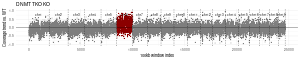

In [9]:
p <- ggplot() + geom_point(data = plot_df, aes(window, trend_diff, color = trisomy), size = 0.5) + theme_minimal(base_size = 15) + 
         geom_hline(yintercept = 0) + ylim(-1,1) + 
         geom_text(data = label_df, aes(x = window, y = 0.8, label = label)) + 
         xlab("100kb window index") + ylab("Coverage trend vs. WT") + ggtitle(nm) + 
         scale_color_identity()

for (i in 1:length(chrom_lims)){
    p = p + geom_vline(xintercept = chrom_lims[i], lty = 2)
}

options(repr.plot.width = 15, repr.plot.height = 3)
show_fig("./figs/Supp/DNMT_TKO_trisomies.pdf", p, width = 15, height = 3)

**ED 4a, Dnmt-TKO row**: `figs/Supp/DNMT_TKO_trisomies.pdf`. chr6 sits above zero.

## ED 6b: state-specific CRE clusters

- Input: ATAC model `data/output/mod.RDS` (from `init()` in `Fig4.ipynb`).
- `build_peak_mat()` (`scripts/ATAC_preprocessing.r`): reads per peak per pooled state for WT, Dnmt-TKO, Dnmt-DKO, Tet-TKO, trisomy-corrected and scaled to common coverage.
- Keeps distal CREs (> 5 kb from a TSS); drops `marginal`, `pmeso.dnmtd`, `gut.dnmt` and columns with < 150,000 reads; log2(read fraction + 1e-6).
- Selects CREs whose WT maximum is > 2 above their median and > -15.
- Clusters with `tglkmeans::TGL_kmeans` (k = 12, seed 29); heatmap shows median-centred values (scale 0 to 2).

In [10]:
library(tidyr)

In [11]:
mod = readRDS(in_path("./data/output/mod.RDS"))

In [12]:
mat_list = list()
for (this_state in mod$cov_states){
    mat = build_peak_mat(mod = mod, peaks = mod$npeaks, state = this_state, ignore_dko_dsamp = F)
    mat_f = mat[,c("wt", "dnmt", "dnmtd", "tet")]
    colnames(mat_f) = paste(colnames(mat_f), this_state, sep = "-")
    mat_list[[this_state]] = mat_f
}

In [13]:
for (nm in names(mat_list)){
    mat_mod = mat_list[[nm]]
    colnames(mat_mod) = gsub(paste0("-", nm), "", colnames(mat_mod))
    mat_list[[nm]] = mat_mod
}

In [14]:
names_to_keep = setdiff(names(mat_list), c("marginal"))

In [15]:
f_cre = mod$npeaks$d_tss > 5e+3

In [16]:
cre_all = do.call(cbind, mat_list[names_to_keep])
cols_to_keep = setdiff(colnames(cre_all), c("pmeso.dnmtd", "gut.dnmt"))
cre_all = cre_all[f_cre, cols_to_keep]

In [17]:
cre_all = cre_all[,colSums(cre_all) > 150000]

In [18]:
cre_all = apply(cre_all, 2, function(x) {log2((x/sum(x)) + 1e-6)})

In [19]:
wt_cols = grep(".wt", colnames(cre_all), v=T)
f_var = apply(cre_all[,wt_cols], 1, function(x) {(max(x)-median(x) > 2) & max(x)>-15})

In [20]:
km = tglkmeans::TGL_kmeans(cre_all[f_var,], k=12, id_column=F, seed = 29)

In [21]:
cre_var = cre_all[f_var,]
cre_var_km = tgs_matrix_tapply(t(cre_var), km$cluster, mean)

In [22]:
annot = data.frame("colname" = colnames(cre_var_km)) %>% mutate(state = sub("\\..*", "", colname), mut = sub(".*\\.", "", colname)) %>%
    column_to_rownames("colname")
annot_colors = list("state" = c("rnp" = "#649146", "exe_meso" = "#8870ad", "ac_prog" = "#cc7818",
  "ac" = "#824A09", "haem_prog" = "#FBBE92", "lnm" = "#DFCDE4", "pmeso" = "#408DA1",
  "card_meso" = "#53f1fc", "se" = "#f7f79e", "gut" = "#EF5A9D"),
                    "mut" = c("wt" = "grey50", "tet" = "red", "dnmtd" = "lightblue", "dnmt" = "blue"))

colors = colorRampPalette(c("grey95", "lightblue1", "lightblue2", "deepskyblue2", "deepskyblue4"))(1001)

In [23]:
phtmp = t(apply(cre_var, 1, function(x) {x-median(x)}))
stat_order = c("se", "rnp", "lnm", "pmeso", "card_meso", "exe_meso", "ac_prog", "haem_prog", "gut")
annot = annot %>% arrange(factor(state, levels = stat_order))

phtmp = phtmp[,rownames(annot)]

In [24]:
cre_var_km_fc = t(apply(cre_var_km, 1, function(x) {x-median(x)}))
cluster_order = names(sort(apply(cre_var_km_fc[,rownames(annot)], 1, which.max)))

In [25]:
row_order_dict = km$cluster[order(match(km$cluster, cluster_order))]
row_order = names(row_order_dict)

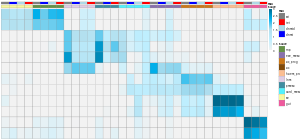

In [26]:
options(repr.plot.width = 15, repr.plot.height = 7)
pheatmap::pheatmap(cre_var_km_fc[cluster_order,rownames(annot)], annotation_col = annot, annotation_colors = annot_colors,
                   cluster_cols = F, cluster_rows = F,
                   show_rownames = F, show_colnames = F, col = colors, breaks = seq(0,3,l=999))

Cluster means, used only to order clusters by peak column; not saved.

In [27]:
gaps_row <- unname(c(1, which(row_order_dict[-1] != row_order_dict[-length(row_order_dict)]) + 1))

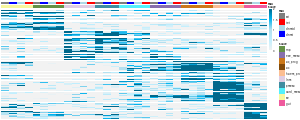

In [28]:
options(repr.plot.width = 15, repr.plot.height = 6)

show_fig("./figs/Supp/CRECLs.pdf", draw = pheatmap::pheatmap(phtmp[row_order,], annotation_col = annot, annotation_colors = annot_colors,
                   cluster_cols = F, cluster_rows = F, gaps_row = gaps_row,
                   show_rownames = F, show_colnames = F, col = colors, breaks = seq(0,2,l=1000), 
                   width = 15, height = 6))

**ED 6b**: one row per CRE, grouped by cluster: `figs/Supp/CRECLs.pdf` (no inline output).